 # Analyzing Employee Data for a Tech Company

Load Dataset

In [22]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('E:\BRAINWORk\Machine Learning\placement-project\DataSets\employees_data.csv')

<>:6: SyntaxWarning: invalid escape sequence '\B'
<>:6: SyntaxWarning: invalid escape sequence '\B'
C:\Users\Snehal\AppData\Local\Temp\ipykernel_23520\1768722655.py:6: SyntaxWarning: invalid escape sequence '\B'
  df = pd.read_csv('E:\BRAINWORk\Machine Learning\placement-project\DataSets\employees_data.csv')


In [2]:
df.head()

,EmployeeID,Age,Gender,Location,JobTitle,Salary
0,1,29,Male,Austin,HR Manager,198686.20
1,2,41,Male,Austin,HR Manager,60732.45
2,3,33,Female,Seattle,Software Engineer,142708.49
3,4,46,Female,New York,Project Manager,178784.12
4,5,25,Male,Austin,Project Manager,88112.93


In [3]:
df.shape

(100, 6)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   EmployeeID  100 non-null    int64  
 1   Age         100 non-null    int64  
 2   Gender      100 non-null    object 
 3   Location    100 non-null    object 
 4   JobTitle    100 non-null    object 
 5   Salary      100 non-null    float64
dtypes: float64(1), int64(2), object(3)
memory usage: 4.8+ KB


In [5]:
df.describe()

,EmployeeID,Age,Salary
count,100.000000,100.00000,100.000000
mean,50.500000,42.71000,128117.620900
std,29.011492,10.42946,37795.462034
min,1.000000,25.00000,60732.450000
25%,25.750000,33.00000,93961.727500
50%,50.500000,44.00000,123597.780000
75%,75.250000,52.00000,157923.512500
max,100.000000,60.00000,198686.200000


In [7]:
df.columns

Index(['EmployeeID', 'Age', 'Gender', 'Location', 'JobTitle', 'Salary'], dtype='object')

In [8]:
df.isnull().sum()

EmployeeID    0
Age           0
Gender        0
Location      0
JobTitle      0
Salary        0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

Data Cleaning

In [ ]:
# Remove Duplicates

df.drop_duplicates(inplace=True)

In [12]:
# Handle Missing Values

df['Age'].fillna(df['Age'].median(), inplace=True)

C:\Users\Snehal\AppData\Local\Temp\ipykernel_23520\807038211.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(), inplace=True)


Employee Demographics

Age Distribution

In [13]:
df['Age'].describe()

count    100.00000
mean      42.71000
std       10.42946
min       25.00000
25%       33.00000
50%       44.00000
75%       52.00000
max       60.00000
Name: Age, dtype: float64

<Axes: xlabel='Age', ylabel='Count'>

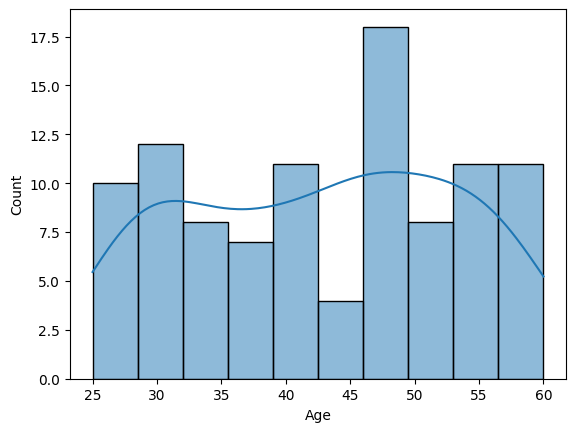

In [16]:
sns.histplot(df['Age'], bins=10, kde=True)

Gender Distribition

In [17]:
df['Gender'].value_counts()

Gender
Male      53
Female    47
Name: count, dtype: int64

<Axes: xlabel='Gender', ylabel='count'>

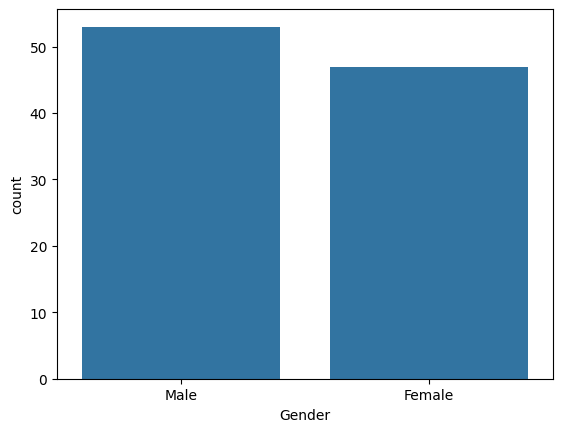

In [18]:
sns.countplot(x='Gender',data=df)

Location Distribution

In [19]:
df['Location'].value_counts()

Location
New York         23
Chicago          23
Austin           20
Seattle          20
San Francisco    14
Name: count, dtype: int64

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Austin'),
  Text(1, 0, 'Seattle'),
  Text(2, 0, 'New York'),
  Text(3, 0, 'San Francisco'),
  Text(4, 0, 'Chicago')])

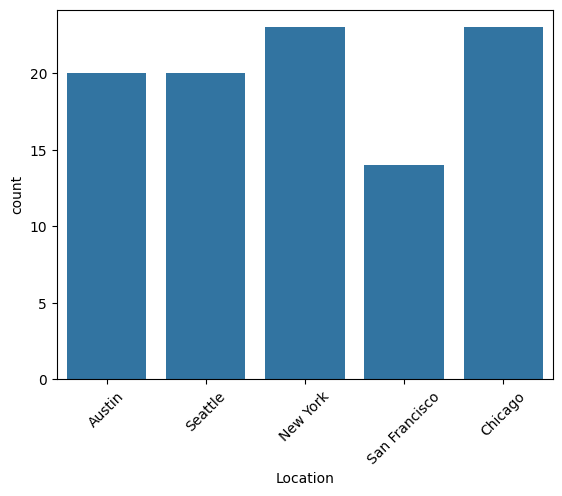

In [23]:
sns.countplot(x='Location', data = df)
plt.xticks(rotation=45)

Average salary by job Title

In [24]:
df.groupby('JobTitle')['Salary'].mean().sort_values(ascending=False)

JobTitle
Project Manager      143201.954000
HR Manager           130284.838125
Software Engineer    123308.163333
Data Scientist       123259.875200
DevOps Engineer      121788.738333
Name: Salary, dtype: float64

([0, 1, 2, 3, 4],
 [Text(0, 0, 'HR Manager'),
  Text(1, 0, 'Software Engineer'),
  Text(2, 0, 'Project Manager'),
  Text(3, 0, 'DevOps Engineer'),
  Text(4, 0, 'Data Scientist')])

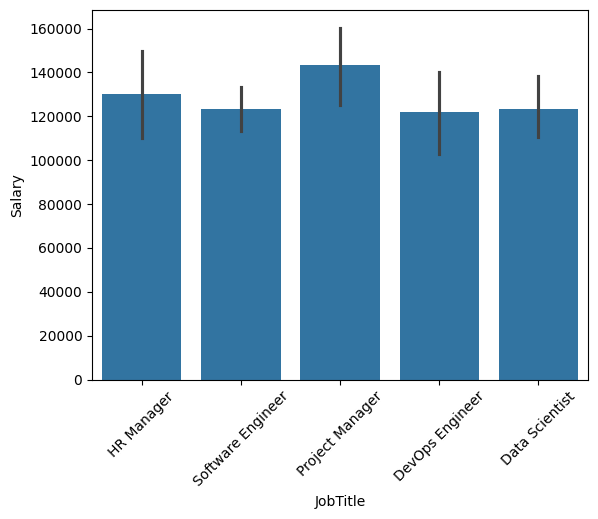

In [25]:
sns.barplot(
    x='JobTitle',
    y='Salary',
    data=df
)
plt.xticks(rotation=45)

Salary by Location

In [26]:
df.groupby('Location')['Salary'].mean().sort_values(ascending=False)

Location
Seattle          135643.638000
San Francisco    129880.460000
Chicago          129783.353913
New York         127754.850870
Austin           117859.209000
Name: Salary, dtype: float64

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Austin'),
  Text(1, 0, 'Seattle'),
  Text(2, 0, 'New York'),
  Text(3, 0, 'San Francisco'),
  Text(4, 0, 'Chicago')])

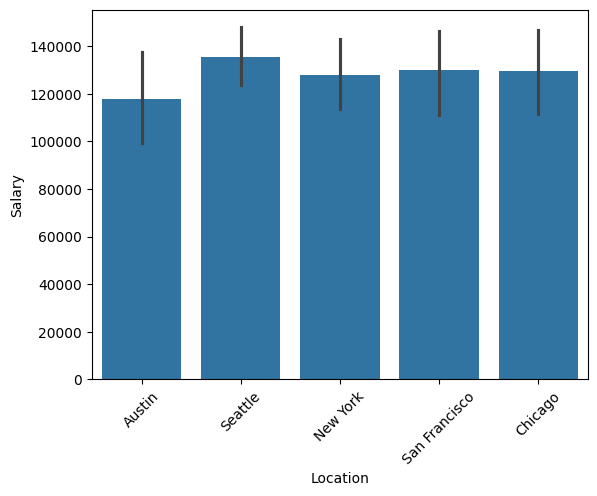

In [27]:
sns.barplot(
    x='Location',
    y='Salary',
    data = df
)
plt.xticks(rotation=45)

Salary Distribution

<Axes: xlabel='Salary', ylabel='Count'>

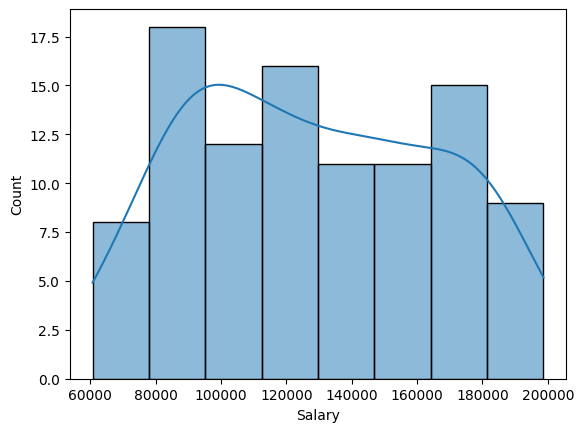

In [29]:
sns.histplot(df['Salary'], kde=True)

Salary Outliers

<Axes: xlabel='Salary'>

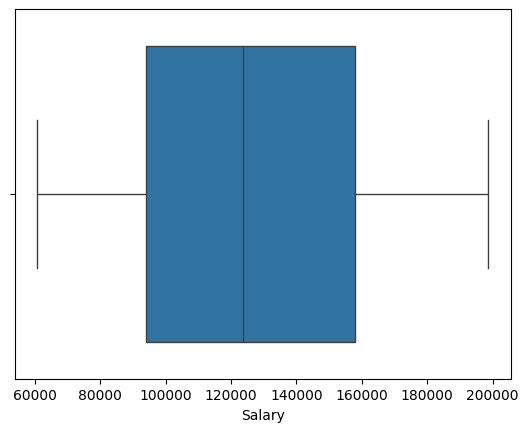

In [30]:
sns.boxplot(x=df['Salary'])

Correlation Analysis

In [31]:
df.corr(numeric_only=True)

,EmployeeID,Age,Salary
EmployeeID,1.000000,0.004557,-0.303188
Age,0.004557,1.000000,0.024904
Salary,-0.303188,0.024904,1.000000


<Axes: >

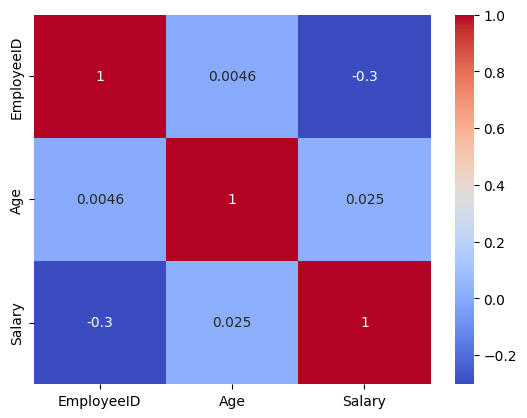

In [32]:
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

Pivot Table

In [34]:
pd.pivot_table(
    df,
    values='Salary',
    index='JobTitle',
    columns='Gender',
    aggfunc='mean'
)

Gender,Female,Male
JobTitle,,
Data Scientist,133732.092727,115031.704286
DevOps Engineer,134286.798000,106166.163750
HR Manager,149123.255000,118981.788000
Project Manager,144451.531111,142179.572727
Software Engineer,117111.043636,130124.995000
